In [1]:
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer

pd.set_option('display.max_columns', 50)

### 0. <u>Reading .hea files</u>
- Creating initial **all_data** dictionary
- flatten this to make a dataframe
- **note**: cesareans are already dropped from del_cs.sh script

In [2]:
all_data = {}
for hea_file in glob.glob("data/all_data/*.hea"):
    with open(hea_file, "r") as f:
        last_line = None
        entry = None
        signal_cnt=0
        last_line_cnt = -2
        last_line_dict = {
            0: "outcome_msr",
            1: "neatology_outcome_msr",
            2: "fetus_desc",
            3: "maternal_factors",
            4: "delivery_desc",
            5: "signal_inf",
        }

        for line in f:
            if line=='\n':
                continue

            if line.startswith("#-"):
                last_line_cnt+=1
                last_line = line
                if last_line_cnt>=0:
                    all_data[entry][last_line_dict[last_line_cnt]] = {}
                continue

            if not entry:
                entry, n_signals, data_format, sample_freq = line.split()
                signals = f""
                all_data[entry] = {"metadata": {"id": int(entry),
                                                "n_signals": int(n_signals),
                                                "sample_freq": int(data_format),
                                                "n_samples": int(sample_freq)}}

            elif not last_line:
                signal_cnt+=1
                file, signal_res, gain_baseline_units, adc_res, adc_zero_val, init_val, n_samples, timing_offset, fetal_hr = line.split()

                baseline=None
                
                if "(" in gain_baseline_units:
                    gain, rest = gain_baseline_units.split("(")
                    baseline, rest = rest.split(")")
                    units = rest[1:]
                else:
                    gain, units = gain_baseline_units.split("/")

                try: 
                    baseline = int(baseline)
                except:
                    pass

                all_data[entry][f"signal_{signal_cnt}"] = {"file": file,
                                                    "signal_res": int(signal_res),
                                                    "gain": int(gain),
                                                    "baseline": baseline,
                                                    "units": units,
                                                    }

            else:
                *key, val = line.split()
                key = ("").join(key)[1:]
                try:
                    val = float(val)
                except ValueError:
                    pass
                all_data[entry][last_line_dict[last_line_cnt]][key] = val

In [3]:
def flatten_dict(d, parent_key=''):
    items = {}
    for k, v in d.items():
        new_key = f"{parent_key}.{k}" if parent_key else k
        if isinstance(v, dict):
            items.update(flatten_dict(v, new_key))
        else:
            items[new_key] = v
    return items

In [4]:
rows = []
for record_id, record_dict in all_data.items():
    flattened = flatten_dict(record_dict)
    rows.append(flattened)

df = pd.DataFrame(rows)

### 1. <u>Creating the target feature</u>

- **Fetus state**: Based on  $\mathrm{pH}$ levels
    - Normal if $ \mathrm{pH} \in [7.20, 7.35] $
    - Counts: **306 normal** (60.47%) and **200 abnormal** (39.53%)
    - $\mathrm{pH}$ appears to follow a left skewed distribution

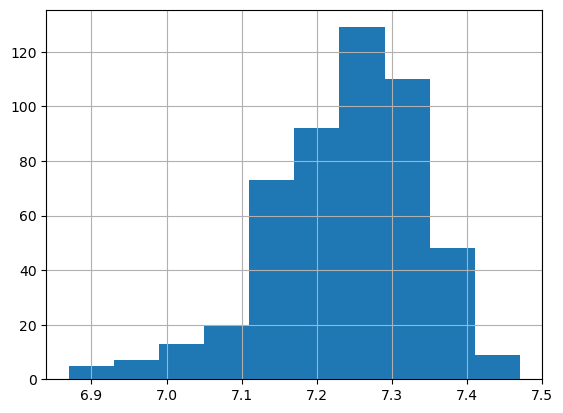

In [5]:
try:
    df['fetal_state'] = np.where((df['outcome_msr.pH'] >= 7.2) & (df['outcome_msr.pH'] <= 7.35), 'normal', 'abnormal')
    df["outcome_msr.pH"].hist()
except:
    pass

In [6]:
print(df["fetal_state"].value_counts())
print(df["fetal_state"].value_counts(normalize=True))

fetal_state
normal      306
abnormal    200
Name: count, dtype: int64
fetal_state
normal      0.604743
abnormal    0.395257
Name: proportion, dtype: float64


### 2. <u>Dropping Constant Features</u> 

- **n_signals**: 2
  - Fetal heart rate time series
  - Uterine contraction signal
- **Sampling rate**: 4 Hz
- **Other Constant Features**: standard for every data instance:
  - Signal Gain = 100
  - Signal Baseline = 0

In [7]:
cols_to_drop = []

col_width = max(len(col) for col in df.columns) + 2

for col in df.columns:
    if df[col].nunique() == 1:
        cols_to_drop.append(col)
        print(f"{col:<{col_width}}{df[col].unique()[0]}")

try:
    df.drop(columns=cols_to_drop, inplace=True)
except:
    pass

metadata.n_signals                2
metadata.sample_freq              4
signal_1.signal_res               16
signal_1.gain                     100
signal_1.baseline                 0
signal_1.units                    bpm
signal_2.signal_res               16
signal_2.gain                     100
signal_2.units                    nd
neatology_outcome_msr.NICUdays    0.0
neatology_outcome_msr.Seizures    0.0
neatology_outcome_msr.HIE         0.0
neatology_outcome_msr.Intubation  0.0
neatology_outcome_msr.Maindiag.   0.0
neatology_outcome_msr.Otherdiag.  0.0
delivery_desc.Deliv.type          1.0
signal_inf.Sig2Birth              0.0


### 3. <u>Dropping unrelated Features</u> 
- **signal 1 & signal 2 files**: Same as id that is kept to match later tabular with signals
- more unrelated variables like database ID, and number of samples

In [8]:
# droppin other variables that we don't need

rest_cols_to_drop =[
    'signal_1.file', # already containing id for matching with .dat file 
    'signal_2.file', # already containing id for matching with .dat file 
    'signal_2.baseline', # everything is nan
    "signal_inf.dbID", # db id
]
try:
    df.drop(columns=rest_cols_to_drop, inplace=True)
except:
    pass

<Axes: >

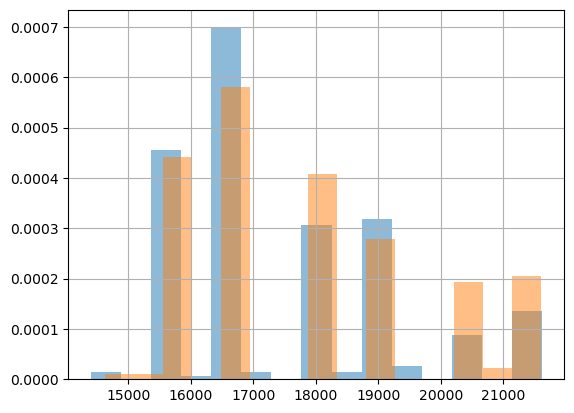

In [9]:
# figuring out if shorter or longer samples have something to do with fetal state 
# (eg taking longer due to a problem)
# won't be used since it is kind of metadata

df[df["fetal_state"]=="normal"]["metadata.n_samples"].hist(density=True, bins=15, alpha=0.5)
df[df["fetal_state"]=="abnormal"]["metadata.n_samples"].hist(density=True, bins=15, alpha=0.5)

In [11]:
if "metadata.n_samples" in df.columns:
    # Calculate percentiles of n_samples
    percentile_bins = np.arange(0, 1.0, 0.1)  # 0% to 90%
    n_samples = df["metadata.n_samples"]
    percentile_values = np.quantile(n_samples, percentile_bins)

    # Store results
    results = []

    for i in range(len(percentile_values)-1):
        lower = percentile_values[i]
        upper = percentile_values[i+1]
        
        bin_df = df[(df["metadata.n_samples"] > lower) & (df["metadata.n_samples"] <= upper)]
        
        if len(bin_df) == 0:
            continue  # skip empty bins
        
        counts = bin_df["fetal_state"].value_counts(normalize=True)  # percentage
        results.append({
            "bin_range": f"{lower:.0f}-{upper:.0f}",
            "healthy_pct": counts.get("normal", 0) * 100,
            "unhealthy_pct": counts.get("abnormal", 0) * 100,
            "n_records": len(bin_df)
        })

    # Convert to DataFrame for easy viewing
    results_df = pd.DataFrame(results)
    print(results_df)

     bin_range  healthy_pct  unhealthy_pct  n_records
0  14400-15600    60.747664      39.252336        107
1  15600-16800    66.459627      33.540373        161
2  16800-18000    55.421687      44.578313         83
3  18000-18020    33.333333      66.666667          3
4  18020-19200    66.216216      33.783784         74
5  19200-20400    48.484848      51.515152         33


In [12]:
try:
    df = df.drop(columns=["metadata.n_samples"])
except:
    pass

### 4. <u>Dropping outcome measures</u> 

- They are measured after the birth, where the outcome is already known

In [13]:
# outcome measures will be dropped, cant be used as predictors 
# since they are measured after the birth, where the outcome is already known
# pH levels belong here so it is handled as well

outcome_cols = [col for col in df.columns if "outcome_msr" in col]
try:
    df = df.drop(columns=outcome_cols)
except:
    pass

### 5. <u>Handling fetus features</u>

- **Sex**: one-hot encoded; will be dealt with during feature selection  
- **Weight & weeks**:  
    - Since there are no predefined upper or lower limits, **standardization** will be applied:  

      $$
      z = \frac{x - \mu}{\sigma}
      $$

      where  
      - $x$: original value  
      - $\mu$: mean of the feature  
      - $\sigma$: standard deviation of the feature

In [14]:
fetus_desc_cols = [col for col in df.columns if 'fetus_desc' in col]
fetus_desc_cols

['fetus_desc.Gest.weeks', 'fetus_desc.Weight(g)', 'fetus_desc.Sex']

In [ ]:
# most likely 1 == male
df.groupby('fetus_desc.Sex')['fetus_desc.Weight(g)'].describe()

,count,mean,std,min,25%,50%,75%,max
fetus_desc.Sex,,,,,,,,
1.0,261.0,3469.616858,447.308883,2030.0,3230.0,3470.0,3780.0,4750.0
2.0,245.0,3314.326531,438.872502,1970.0,3040.0,3330.0,3610.0,4510.0


In [16]:
# not necessarily strong feature but going to keep for now
df.groupby('fetus_desc.Sex')['fetal_state'].describe()

,count,unique,top,freq
fetus_desc.Sex,,,,
1.0,261,2,normal,164
2.0,245,2,normal,142


In [17]:
if "is_male" not in df.columns:
    df["is_male"] = np.where(df["fetus_desc.Sex"]==1, 1, 0)
try:
    df.drop(columns=["fetus_desc.Sex"], inplace=True)
except:
    pass

In [18]:
if "fetal_weight" not in df.columns:
    try:
        mean = df["fetus_desc.Weight(g)"].mean()
        std = df["fetus_desc.Weight(g)"].std()
        df['fetal_weight'] = (df["fetus_desc.Weight(g)"]-mean)/std
        df.drop(columns = ["fetus_desc.Weight(g)"], inplace=True)
    except:
        print("fetal_weight is missing and didnt manage to create it")

In [19]:
if "weeks" not in df.columns:
    try:
        mean = df["fetus_desc.Gest.weeks"].mean()
        std = df["fetus_desc.Gest.weeks"].std()
        df['weeks'] = (df["fetus_desc.Gest.weeks"]-mean)/std
        df.drop(columns = ["fetus_desc.Gest.weeks"], inplace=True)
    except:
        print("weeks is missing and didnt manage to create it")

### 6. <u>Handling maternal features</u>

- **Parity**: number of successful previous births  
- **Gravidity**: total number of pregnancies (including the current one)  
    - These two features are expected to be highly correlated; both will be kept, and correlation will be addressed later.  
    - For cases where $ \mathrm{Gravidity} > 1 $,  
      the number of unsuccessful births is computed as  
      $$ \text{Unsuccessful births} = \mathrm{Gravidity} - 1 - \mathrm{Parity} $$
- **Age**: standardized as mentioned above
- **Diabetes**: small sample size (6.5% with diabetes) -> Dropped
- **Hypertension**: a bit bigger sample size (8.3%) -> kept
- **Preeclampsia** : really small sample size (3.2%) -> Dropped
- **Liq.praecox**: Good sample size (28.1%)-> Kept
- **Pyrexia**: really small sample size (~1.0%) -> Dropped
- **Meconium**: Good sample size (11.3%)-> Kept

In [20]:
maternal_desc_cols = [col for col in df.columns if 'maternal_factors' in col]
maternal_desc_cols

['maternal_factors.Age',
 'maternal_factors.Gravidity',
 'maternal_factors.Parity',
 'maternal_factors.Diabetes',
 'maternal_factors.Hypertension',
 'maternal_factors.Preeclampsia',
 'maternal_factors.Liq.praecox',
 'maternal_factors.Pyrexia',
 'maternal_factors.Meconium']

In [22]:
df["prev_failed_pregnancy"] = np.where(
    ((df["maternal_factors.Parity"] != df["maternal_factors.Gravidity"] - 1)
     & (df["maternal_factors.Gravidity"] != 1)),
    1, 0
)

print("Stats for materals that HAVE NOT FAILED a privacy before (given thats its not their first birth)")
print(df[(df["prev_failed_pregnancy"]==0) & (df["maternal_factors.Gravidity"]>1)] ["fetal_state"].value_counts())
print(df[df["prev_failed_pregnancy"]==0]["fetal_state"].value_counts(normalize=True))

print()
print("Stats for materals that HAVE FAILED a privacy before (given thats its not their first birth)")
print(df[df["prev_failed_pregnancy"]==1]["fetal_state"].value_counts())
print(df[df["prev_failed_pregnancy"]==1]["fetal_state"].value_counts(normalize=True))

Stats for materals that HAVE NOT FAILED a privacy before (given thats its not their first birth)
fetal_state
normal      15
abnormal     6
Name: count, dtype: int64
fetal_state
normal      0.610048
abnormal    0.389952
Name: proportion, dtype: float64

Stats for materals that HAVE FAILED a privacy before (given thats its not their first birth)
fetal_state
normal      51
abnormal    37
Name: count, dtype: int64
fetal_state
normal      0.579545
abnormal    0.420455
Name: proportion, dtype: float64


In [23]:
# reduce cardinallity and rare categories
first_birth = (df['maternal_factors.Gravidity']==1).sum()
not_fisrt_birth = (df['maternal_factors.Gravidity']!=1).sum() #or nan

print(f"First Birth: {first_birth}")
print(f"Not First Birth or nan: {not_fisrt_birth}")

First Birth: 397
Not First Birth or nan: 109


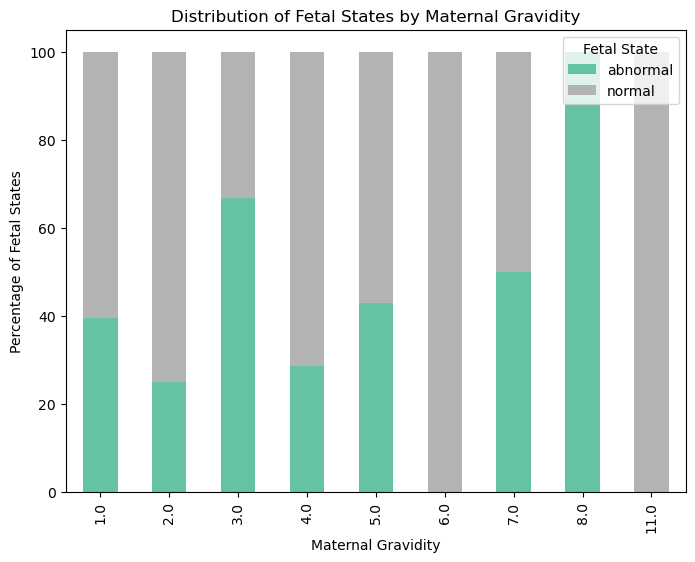

In [24]:
# Not significant ability to separate, but keeping is_first_birth = 1 or 0
# So we can filter it later with selection techniques

# Compute counts per category
counts = df.groupby(['maternal_factors.Gravidity', 'fetal_state']).size().unstack(fill_value=0)

# Convert to percentages
counts_pct = counts.div(counts.sum(axis=1), axis=0) * 100

# Plot
counts_pct.plot(kind='bar', stacked=True, figsize=(8,6), colormap='Set2')
plt.ylabel("Percentage of Fetal States")
plt.xlabel("Maternal Gravidity")
plt.title("Distribution of Fetal States by Maternal Gravidity")
plt.legend(title='Fetal State')
plt.show()

In [25]:
if 'is_first_birth' not in df.columns:
    df["is_first_birth"] = np.where(df["maternal_factors.Gravidity"]==1, 1, 0)
try:
    df.drop(columns=["maternal_factors.Gravidity"], inplace=True)
except:
    pass

In [26]:
df["is_first_birth"].value_counts()

is_first_birth
1    397
0    109
Name: count, dtype: int64

In [ ]:
if "age" not in df.columns:
    try:
        mean = df["maternal_factors.Age"].mean()
        std = df["maternal_factors.Age"].std()
        df['age'] = (df["maternal_factors.Age"]-mean)/std
        df.drop(columns = ["maternal_factors.Age"], inplace=True)
    except:
        print("age is missing and didnt manage to create it")

In [28]:
# this feature is going to be highly correlated with is_first_birth,
# but it's going to be to handled later

print("Not given birth before")
print(df[df["maternal_factors.Parity"]==0]["fetal_state"].value_counts(normalize=True))
print("Given Birth before")
print(df[df["maternal_factors.Parity"]>0]["fetal_state"].value_counts(normalize=True))

Not given birth before
fetal_state
normal      0.591176
abnormal    0.408824
Name: proportion, dtype: float64
Given Birth before
fetal_state
normal      0.63253
abnormal    0.36747
Name: proportion, dtype: float64


In [29]:
if "prev_birth" not in df.columns:
    df["prev_birth"] = np.where(df["maternal_factors.Parity"]>0, 1, 0)
try:
    df.drop(columns=["maternal_factors.Parity"], inplace=True)
except:
    pass

In [30]:
# small sample size of diabetes instances and counter intuitive
# dropping

print(df['maternal_factors.Diabetes'].value_counts(normalize=True))
print(df['maternal_factors.Diabetes'].value_counts())

print()
print(df.groupby("maternal_factors.Diabetes")["fetal_state"].value_counts(normalize=True))

maternal_factors.Diabetes
0.0    0.934783
1.0    0.065217
Name: proportion, dtype: float64
maternal_factors.Diabetes
0.0    473
1.0     33
Name: count, dtype: int64

maternal_factors.Diabetes  fetal_state
0.0                        normal         0.596195
                           abnormal       0.403805
1.0                        normal         0.727273
                           abnormal       0.272727
Name: proportion, dtype: float64


In [31]:
try:
    df.drop(columns=["maternal_factors.Diabetes"], inplace=True)
except:
    pass

In [32]:
# still small sample size but improved 
# keeping for now

print(df['maternal_factors.Hypertension'].value_counts(normalize=True))
print(df['maternal_factors.Hypertension'].value_counts())

print()
print(df.groupby("maternal_factors.Hypertension")["fetal_state"].value_counts(normalize=True))

maternal_factors.Hypertension
0.0    0.916996
1.0    0.083004
Name: proportion, dtype: float64
maternal_factors.Hypertension
0.0    464
1.0     42
Name: count, dtype: int64

maternal_factors.Hypertension  fetal_state
0.0                            normal         0.607759
                               abnormal       0.392241
1.0                            normal         0.571429
                               abnormal       0.428571
Name: proportion, dtype: float64


In [33]:
# just rename

df.rename(columns={"maternal_factors.Hypertension": "hypertension"}, inplace=True, errors="pass")

In [34]:
# really small sample size
# dropping

print(df['maternal_factors.Preeclampsia'].value_counts(normalize=True))
print(df['maternal_factors.Preeclampsia'].value_counts())

print()
print(df.groupby("maternal_factors.Preeclampsia")["fetal_state"].value_counts(normalize=True))

maternal_factors.Preeclampsia
0.0    0.968379
1.0    0.031621
Name: proportion, dtype: float64
maternal_factors.Preeclampsia
0.0    490
1.0     16
Name: count, dtype: int64

maternal_factors.Preeclampsia  fetal_state
0.0                            normal         0.602041
                               abnormal       0.397959
1.0                            normal         0.687500
                               abnormal       0.312500
Name: proportion, dtype: float64


In [35]:
try:
    df.drop(columns=["maternal_factors.Preeclampsia"], inplace=True)
except:
    pass

In [36]:
print(df['maternal_factors.Liq.praecox'].value_counts(normalize=True))
print(df['maternal_factors.Liq.praecox'].value_counts())

print()
print(df.groupby("maternal_factors.Liq.praecox")["fetal_state"].value_counts(normalize=True))

maternal_factors.Liq.praecox
0.0    0.719368
1.0    0.280632
Name: proportion, dtype: float64
maternal_factors.Liq.praecox
0.0    364
1.0    142
Name: count, dtype: int64

maternal_factors.Liq.praecox  fetal_state
0.0                           normal         0.615385
                              abnormal       0.384615
1.0                           normal         0.577465
                              abnormal       0.422535
Name: proportion, dtype: float64


In [37]:
df.rename(columns={"maternal_factors.Liq.praecox": "early_rupture"}, inplace=True, errors="pass")

In [38]:
print(df['maternal_factors.Pyrexia'].value_counts(normalize=True))
try:
    df.drop(columns=["maternal_factors.Pyrexia"], inplace=True)
except:
    pass

maternal_factors.Pyrexia
0.0    0.990119
1.0    0.009881
Name: proportion, dtype: float64


In [39]:
print(df['maternal_factors.Meconium'].value_counts(normalize=True))
print()
print(df.groupby("maternal_factors.Meconium")["fetal_state"].value_counts(normalize=True))

maternal_factors.Meconium
0.0    0.887352
1.0    0.112648
Name: proportion, dtype: float64

maternal_factors.Meconium  fetal_state
0.0                        normal         0.608018
                           abnormal       0.391982
1.0                        normal         0.578947
                           abnormal       0.421053
Name: proportion, dtype: float64


In [40]:
df.rename(columns={"maternal_factors.Meconium": "meconium"}, inplace=True, errors="pass")

### 7. <u>Handling delivery descriptors</u>
- **Presentation**: normal presentation (head) vs rest (rest are rare)
- **Induced**: appears to have good sample with some difference in the normal/abnormal mean
- **Stage I and stage II**: 
    - keeping an index to show where phase one ends and phase two starts 
    - keeping the duration of each stage as normalized value
    - keeping the fraction of the first stage as percentange of both stages
    - Those will introduce some redundancy but redundancies will removed on feature selection stage
- **No Progress**: Although rare, appears to give noticable difference, specifically increased number of abnormal
- **CK/KP**: Extremely rare -> drop


In [41]:
deliv_desc_col = [col for col in df.columns if "delivery_desc" in col]
deliv_desc_col

['delivery_desc.Presentation',
 'delivery_desc.Induced',
 'delivery_desc.I.stage',
 'delivery_desc.NoProgress',
 'delivery_desc.CK/KP',
 'delivery_desc.II.stage']

In [42]:
print(df['delivery_desc.Presentation'].value_counts(normalize=True))
print()
print(df.groupby("delivery_desc.Presentation")["fetal_state"].value_counts(normalize=True))

delivery_desc.Presentation
1.0    0.918489
3.0    0.047714
2.0    0.033797
Name: proportion, dtype: float64

delivery_desc.Presentation  fetal_state
1.0                         normal         0.603896
                            abnormal       0.396104
2.0                         normal         0.647059
                            abnormal       0.352941
3.0                         normal         0.583333
                            abnormal       0.416667
Name: proportion, dtype: float64


In [43]:
if "normal_pres" not in df.columns:
    df["normal_pres"] = np.where(df["delivery_desc.Presentation"]==1, 1, 0)
    df.drop(columns=["delivery_desc.Presentation"], inplace=True)

In [44]:
print(df['delivery_desc.Induced'].value_counts(normalize=True))
print()
print(df.groupby("delivery_desc.Induced")["fetal_state"].value_counts(normalize=True))

delivery_desc.Induced
0.0    0.596838
1.0    0.403162
Name: proportion, dtype: float64

delivery_desc.Induced  fetal_state
0.0                    normal         0.576159
                       abnormal       0.423841
1.0                    normal         0.647059
                       abnormal       0.352941
Name: proportion, dtype: float64


In [45]:
df.rename(columns={"delivery_desc.Induced":"induced"}, inplace=True, errors="pass")

In [46]:
# Rare but strong
print(df['delivery_desc.NoProgress'].value_counts(normalize=True))
print()
print(df.groupby("delivery_desc.NoProgress")["fetal_state"].value_counts(normalize=True))
print(df.groupby("delivery_desc.NoProgress")["fetal_state"].value_counts())

delivery_desc.NoProgress
0.0    0.948617
1.0    0.051383
Name: proportion, dtype: float64

delivery_desc.NoProgress  fetal_state
0.0                       normal         0.610417
                          abnormal       0.389583
1.0                       abnormal       0.500000
                          normal         0.500000
Name: proportion, dtype: float64
delivery_desc.NoProgress  fetal_state
0.0                       normal         293
                          abnormal       187
1.0                       abnormal        13
                          normal          13
Name: count, dtype: int64


In [47]:
df.rename(columns={"delivery_desc.NoProgress":"no_progress"}, inplace=True, errors="pass")

In [48]:
# Really Rare
print(df['delivery_desc.CK/KP'].value_counts(normalize=True))
print()
print(df.groupby("delivery_desc.CK/KP")["fetal_state"].value_counts(normalize=True))
print(df.groupby("delivery_desc.CK/KP")["fetal_state"].value_counts())

delivery_desc.CK/KP
0.0    0.996047
1.0    0.003953
Name: proportion, dtype: float64

delivery_desc.CK/KP  fetal_state
0.0                  normal         0.603175
                     abnormal       0.396825
1.0                  normal         1.000000
Name: proportion, dtype: float64
delivery_desc.CK/KP  fetal_state
0.0                  normal         304
                     abnormal       200
1.0                  normal           2
Name: count, dtype: int64


In [49]:
df.drop(columns=["delivery_desc.CK/KP"], inplace=True, errors="pass")

In [50]:
print(df["delivery_desc.I.stage"].describe())
print()
print(f"Instances with 0 or less minutes in stage 1: {(df["delivery_desc.I.stage"]<=0).sum()}")

count       506.000000
mean        997.096838
std       17480.436498
min         -15.000000
25%         135.000000
50%         215.000000
75%         285.000000
max      393425.000000
Name: delivery_desc.I.stage, dtype: float64

Instances with 0 or less minutes in stage 1: 1


In [51]:
print(df["delivery_desc.II.stage"].describe())
print()
print(f"Instances with 0 or less minutes in stage 1: {(df["delivery_desc.II.stage"]<=0).sum()}")

count    506.000000
mean      13.533597
std        7.575355
min       -1.000000
25%       10.000000
50%       10.000000
75%       20.000000
max       30.000000
Name: delivery_desc.II.stage, dtype: float64

Instances with 0 or less minutes in stage 1: 4


In [52]:
df.loc[df['delivery_desc.I.stage']<=0,'delivery_desc.I.stage'] = np.nan
df.loc[df['delivery_desc.II.stage']<=0,'delivery_desc.II.stage'] = np.nan

In [ ]:
# knn imputation not including the target variable
# normally should exlude a final test set as well to avoid data leakage

features_for_imputation = df.drop(columns=['fetal_state'])
imputer = KNNImputer(n_neighbors=5)
imputed_data = imputer.fit_transform(features_for_imputation)
df_imputed = pd.DataFrame(imputed_data, columns=features_for_imputation.columns, index=df.index)
df[['delivery_desc.I.stage', 'delivery_desc.II.stage']] = imputer.fit_transform(
    df.drop("fetal_state", axis=1)[['delivery_desc.I.stage', 'delivery_desc.II.stage']]
)

In [54]:
df["stage_1_percent"] = df["delivery_desc.I.stage"]/(df["delivery_desc.I.stage"] + df["delivery_desc.II.stage"])

In [55]:
stage_1_mean = df["delivery_desc.I.stage"].mean()
stage_1_std = df["delivery_desc.I.stage"].std()
df["stage_1_normalized"] = (df["delivery_desc.I.stage"]-stage_1_mean)/stage_1_std

In [56]:
stage_2_mean = df["delivery_desc.II.stage"].mean()
stage_2_std = df["delivery_desc.II.stage"].std()
df["stage_2_normalized"] = (df["delivery_desc.II.stage"]-stage_2_mean)/stage_2_std

In [57]:
df.rename(columns={"delivery_desc.II.stage":"stage_2_index"}, inplace=True, errors="pass")
df.drop(columns=["delivery_desc.I.stage"], inplace=True, errors="pass")

### 8. Drop last signal_inf variables and save dataset

In [58]:
df["signal_inf.Pos.II.st."].value_counts()

signal_inf.Pos.II.st.
 14400.0    491
-1.0          4
 14552.0      2
 18630.0      1
 15423.0      1
 17406.0      1
 16200.0      1
 15054.0      1
 19277.0      1
 14561.0      1
 16773.0      1
 17318.0      1
Name: count, dtype: int64

In [59]:
df["signal_inf.Rec.type"].value_counts()

signal_inf.Rec.type
 1.0     380
 2.0      98
 12.0     26
-1.0       2
Name: count, dtype: int64

In [60]:
df.drop(columns=["signal_inf.Pos.II.st.", "signal_inf.Rec.type"], inplace=True, errors="pass")

In [61]:
print(len(df.columns))
df.head()

19


,metadata.id,hypertension,early_rupture,meconium,induced,no_progress,stage_2_index,fetal_state,is_male,fetal_weight,weeks,prev_failed_pregnancy,is_first_birth,age,prev_birth,normal_pres,stage_1_percent,stage_1_normalized,stage_2_normalized
0,1333,0.0,1.0,0.0,0.0,0.0,10.0,normal,1,1.569447,-0.856518,0,1,-0.145180,1,1,0.970588,-0.038178,-0.490791
1,1283,0.0,0.0,0.0,0.0,0.0,30.0,normal,0,-0.343501,0.019034,0,1,-2.148657,0,1,0.922078,-0.036748,2.182410
2,1262,0.0,0.0,0.0,0.0,0.0,5.0,normal,0,-0.966321,0.894585,0,1,-1.258222,0,1,0.964789,-0.049219,-1.159092
3,1303,0.0,0.0,0.0,0.0,0.0,10.0,abnormal,0,0.724191,0.894585,0,1,-1.703440,0,1,0.973190,-0.036291,-0.490791
4,1106,0.0,1.0,0.0,1.0,0.0,10.0,normal,1,1.035601,0.894585,0,1,0.077429,0,1,0.955556,-0.044757,-0.490791


In [62]:
df.to_csv("data/hea.csv")